<a href="https://colab.research.google.com/github/rpasquini/herramientas-econometricas/blob/main/Estructura_del_Error.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Estructura del error: heterocedasticidad, autocorrelación serial y espacial

Este notebook acompaña las slides del Día 4 (Partes A, B y C) y reproduce los números que aparecen en ellas.

Ejemplos: **EAH 2016** (ingreso y escolaridad en CABA), **EMAE** (actividad económica argentina, 1993-2013) y **alquileres temporarios en Ámsterdam**. Además, pequeñas **simulaciones** con verdad conocida, como en los dashboards del libro.

Plan:
1. Datos
2. Heterocedasticidad (EAH)
3. Autocorrelación serial (EMAE)
4. Autocorrelación espacial (Ámsterdam) y un puente con la EAH
5. Práctica

In [1]:
import warnings, io, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, acorr_breusch_godfrey
from statsmodels.stats.stattools import durbin_watson
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.regression.linear_model import GLSAR

warnings.filterwarnings('ignore')

# libpysal / esda / spreg se usan solo en la parte espacial
try:
    import libpysal, esda, spreg
except ImportError:
    %pip install -q libpysal esda spreg openpyxl
    import libpysal, esda, spreg

from libpysal.weights import KNN
from libpysal.weights.spatial_lag import lag_spatial
from esda.moran import Moran
from spreg import OLS, ML_Error, ML_Lag

def quiet(f, *args, **kwargs):
    """Llama a un estimador de spreg sin imprimir."""
    with contextlib.redirect_stdout(io.StringIO()):
        return f(*args, **kwargs)

## 1. Datos
Todo se lee desde el repositorio, así que el notebook corre en Colab sin subir archivos.

In [2]:
base = 'https://raw.githubusercontent.com/rpasquini/herramientas-econometricas/main/datos/'

eah = pd.read_csv(base + 'eah2016_individual.csv')
d = eah[(eah['ingtot_2'] > 0) & (eah['aesc'] != 0) & (eah['aesc'] != 99)].copy()
d['y'] = np.log(d['ingtot_2'])
d['mujer'] = (d['sexo'] == 'mujer').astype(int)
print('EAH, n =', len(d))

EAH, n = 10048


## 2. Heterocedasticidad (EAH)

Modelo: $\log(ingreso)=\beta_0+\beta_1\,aesc+\beta_2\,mujer+\varepsilon$. Comparamos con el mismo modelo con el ingreso **en niveles**.

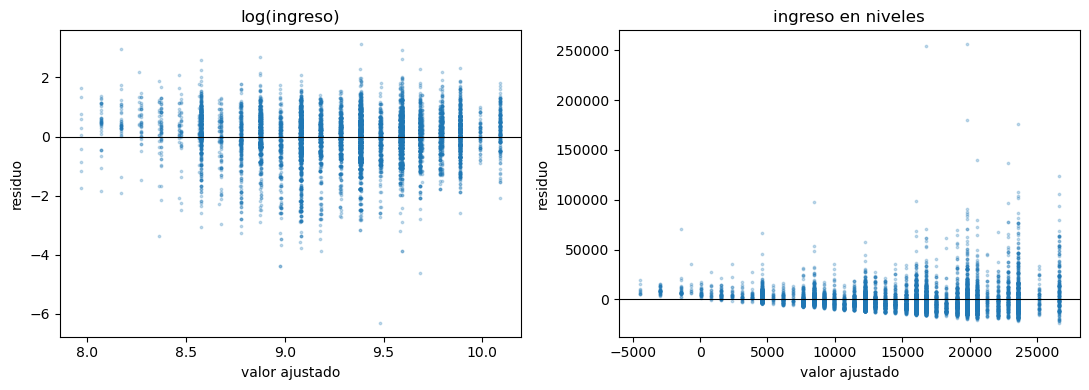

In [3]:
m_log = smf.ols('y ~ aesc + mujer', d).fit()
m_niv = smf.ols('ingtot_2 ~ aesc + mujer', d).fit()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, mm, t in ((ax[0], m_log, 'log(ingreso)'), (ax[1], m_niv, 'ingreso en niveles')):
    a.scatter(mm.fittedvalues, mm.resid, s=3, alpha=.25)
    a.axhline(0, color='k', lw=.8); a.set_xlabel('valor ajustado'); a.set_ylabel('residuo'); a.set_title(t)
plt.tight_layout(); plt.show()

**Tests formales.** Hipótesis nula: homocedasticidad. Ambos rechazan, incluso en logaritmos, porque $n$ es grande.

In [4]:
for nombre, mm in (('log(ingreso)', m_log), ('ingreso (niveles)', m_niv)):
    bp = het_breuschpagan(mm.resid, mm.model.exog)
    wh = het_white(mm.resid, mm.model.exog)
    print(f'{nombre:18s} Breusch-Pagan: {bp[0]:6.1f} (p = {bp[1]:.2g}) | White: {wh[0]:6.1f} (p = {wh[1]:.2g})')

log(ingreso)       Breusch-Pagan:   30.2 (p = 2.8e-07) | White:   36.5 (p = 2.3e-07)
ingreso (niveles)  Breusch-Pagan:   83.8 (p = 6.4e-19) | White:  124.9 (p = 4.7e-26)


¿Importa la magnitud? Desvío del residuo por tramos de escolaridad (en logaritmos):

In [5]:
d['res'] = m_log.resid
print(d.groupby(pd.cut(d['aesc'], [0, 7, 12, 17, 30], labels=['1-7', '8-12', '13-17', '18+']))['res'].std().round(2))

aesc
1-7      0.68
8-12     0.80
13-17    0.72
18+      0.63
Name: res, dtype: float64


**Errores estándar:** convencional, HC1, HC3, clusters por hogar y por comuna. Los coeficientes son los mismos en todas las columnas.

In [6]:
d['hogar'] = pd.factorize(d['id'].astype(str) + '_' + d['nhogar'].astype(str))[0]

def tabla_se(formula):
    base_fit = smf.ols(formula, d).fit()
    especs = {
        'convencional': {},
        'HC1': dict(cov_type='HC1'),
        'HC3': dict(cov_type='HC3'),
        'cluster hogar': dict(cov_type='cluster', cov_kwds={'groups': d['hogar']}),
        'cluster comuna': dict(cov_type='cluster', cov_kwds={'groups': d['comuna']}),
    }
    filas = {}
    for nombre, kw in especs.items():
        r = smf.ols(formula, d).fit(**kw)
        filas[nombre] = {'EE aesc': r.bse['aesc'], 't aesc': r.tvalues['aesc'], 'EE mujer': r.bse['mujer']}
    return base_fit.params[['aesc', 'mujer']], pd.DataFrame(filas).T

for formula in ('y ~ aesc + mujer', 'ingtot_2 ~ aesc + mujer'):
    b, t = tabla_se(formula)
    print(formula, '| coeficientes:', b.round(4).to_dict())
    print(t.round(4).to_string(), '\n')
print('Hogares:', d['hogar'].nunique(), '| comunas:', d['comuna'].nunique())

y ~ aesc + mujer | coeficientes: {'aesc': 0.1015, 'mujer': -0.2962}
                EE aesc   t aesc  EE mujer
convencional     0.0020  50.2802    0.0151
HC1              0.0020  50.8514    0.0150
HC3              0.0020  50.8340    0.0150
cluster hogar    0.0021  48.4668    0.0145
cluster comuna   0.0037  27.4434    0.0203 

ingtot_2 ~ aesc + mujer | coeficientes: {'aesc': 1517.4193, 'mujer': -3797.2297}
                 EE aesc   t aesc  EE mujer
convencional     33.2195  45.6786  248.5460
HC1              37.6898  40.2608  249.9624
HC3              37.7007  40.2491  250.0072
cluster hogar    40.6078  37.3677  229.4892
cluster comuna  114.9610  13.1994  301.5491 

Hogares: 5939 | comunas: 15


**Mínimos cuadrados ponderados (MCG factible).** Estimamos la varianza como $\exp(a+b\,aesc+c\,aesc^2+d\,mujer)$ regresando $\log\hat\varepsilon^2$ y ponderamos por la inversa.

In [7]:
aux = smf.ols('np.log(res**2) ~ aesc + I(aesc**2) + mujer', d).fit()
w = 1 / np.exp(aux.fittedvalues)
m_wls = smf.wls('y ~ aesc + mujer', d, weights=w).fit()
print(pd.DataFrame({'MCO': m_log.params, 'MCP': m_wls.params, 'EE MCO (HC1)': smf.ols('y ~ aesc + mujer', d).fit(cov_type='HC1').bse, 'EE MCP': m_wls.bse}).round(4))

              MCO     MCP  EE MCO (HC1)  EE MCP
Intercept  8.1619  8.1597        0.0281  0.0277
aesc       0.1015  0.1016        0.0020  0.0020
mujer     -0.2962 -0.2965        0.0150  0.0150


**Simulación (como el dashboard).** $y=1+3x+\varepsilon$, con $\varepsilon\sim N(0,(0.5x)^2)$ y $x\sim U(1,10)$. En 1000 muestras de $n=200$ medimos la cobertura del IC al 95% con el error estándar convencional y con HC1.

In [8]:
rng = np.random.default_rng(1)
n, reps, b1 = 200, 1000, 3.0
cov = np.zeros((reps, 2)); est = np.zeros(reps)
for r in range(reps):
    x = rng.uniform(1, 10, n)
    y = 1 + b1 * x + rng.normal(0, 0.5 * x)
    X = sm.add_constant(x)
    f0 = sm.OLS(y, X).fit(); f1 = sm.OLS(y, X).fit(cov_type='HC1')
    est[r] = f0.params[1]
    cov[r] = [abs(f0.params[1] - b1) <= 1.96 * f0.bse[1], abs(f1.params[1] - b1) <= 1.96 * f1.bse[1]]
print(f'media de beta1 = {est.mean():.3f} (verdadero {b1}) | DE = {est.std():.3f}')
print(f'cobertura convencional: {cov[:, 0].mean():.1%} | cobertura HC1: {cov[:, 1].mean():.1%}')

media de beta1 = 3.000 (verdadero 3.0) | DE = 0.087
cobertura convencional: 93.3% | cobertura HC1: 94.9%


## 3. Autocorrelación serial (EMAE)

Modelo: $\log(EMAE_t)=\beta_0+\beta_1\,t+\varepsilon_t$, con $t$ medido en años. $\beta_1$ es la tasa de crecimiento tendencial.

T = 252 | beta1 = 0.0352 (3.6% anual) | EE = 0.0012 | t = 29.3 | R2 = 0.774


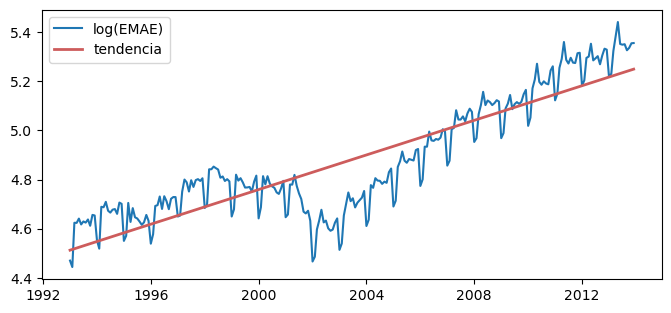

In [9]:
e = pd.read_excel(base + 'series_para_R.xlsx', sheet_name='emae')
e['t'] = np.arange(len(e)) / 12
e['ly'] = np.log(e['EMAE'])
e['mes'] = e['indice_tiempo'].dt.month
T = len(e)

r = smf.ols('ly ~ t', e).fit()
print(f'T = {T} | beta1 = {r.params["t"]:.4f} ({100*(np.exp(r.params["t"])-1):.1f}% anual) | EE = {r.bse["t"]:.4f} | t = {r.tvalues["t"]:.1f} | R2 = {r.rsquared:.3f}')

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(e['indice_tiempo'], e['ly'], label='log(EMAE)'); ax.plot(e['indice_tiempo'], r.fittedvalues, color='indianred', lw=2, label='tendencia')
ax.legend(); plt.show()

**Diagnóstico:** residuos en el tiempo, $e_t$ contra $e_{t-1}$ y función de autocorrelación.

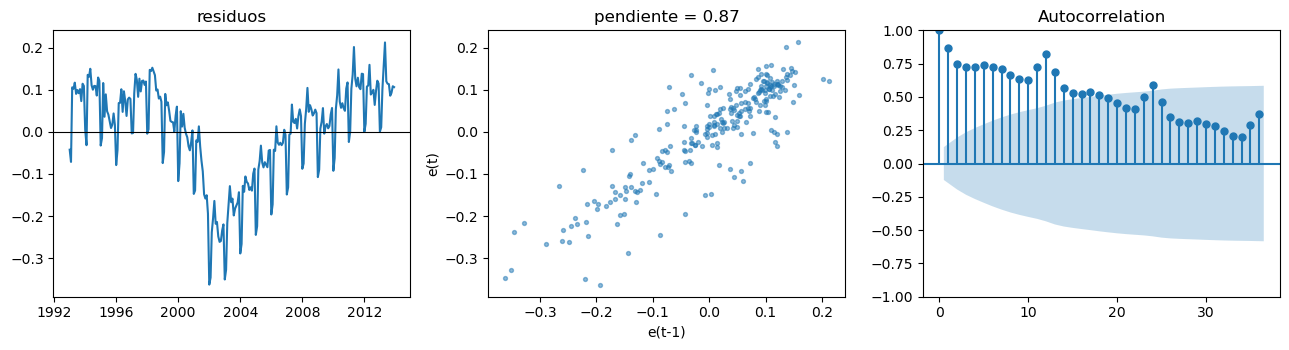

Durbin-Watson = 0.26  (aprox. 2(1-rho) = 0.27)
Breusch-Godfrey (12 rezagos): LM = 221.4, p = 1.2e-40


In [10]:
rho1 = np.corrcoef(r.resid[1:], r.resid[:-1])[0, 1]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].plot(e['indice_tiempo'], r.resid); ax[0].axhline(0, color='k', lw=.8); ax[0].set_title('residuos')
ax[1].scatter(r.resid[:-1], r.resid[1:], s=8, alpha=.5); ax[1].set_xlabel('e(t-1)'); ax[1].set_ylabel('e(t)'); ax[1].set_title(f'pendiente = {rho1:.2f}')
plot_acf(r.resid, lags=36, ax=ax[2]); plt.tight_layout(); plt.show()

bg = acorr_breusch_godfrey(r, nlags=12)
print(f'Durbin-Watson = {durbin_watson(r.resid):.2f}  (aprox. 2(1-rho) = {2*(1-rho1):.2f})')
print(f'Breusch-Godfrey (12 rezagos): LM = {bg[0]:.1f}, p = {bg[1]:.2g}')

**Errores estándar HAC (Newey-West)** con distintos anchos de banda. Con $L=0$ es el estimador de White. La regla $L=\lfloor 4(T/100)^{2/9}\rfloor$ da 4 para $T=252$.

In [11]:
L_auto = int(np.floor(4 * (T / 100) ** (2 / 9)))
filas = {'convencional': (r.bse['t'], r.tvalues['t'])}
for L in (0, L_auto, 12, 24):
    rr = r.get_robustcov_results('HAC', maxlags=L, use_correction=False) if L > 0 else r.get_robustcov_results('HC0')
    filas[f'HAC L={L}'] = (rr.bse[1], rr.tvalues[1])
tab = pd.DataFrame(filas, index=['EE', 't']).T
tab['cociente vs convencional'] = tab['EE'] / r.bse['t']
print(tab.round(4).to_string())

rr12 = r.get_robustcov_results('HAC', maxlags=12, use_correction=False)
print('\nIC 95% convencional:', r.conf_int().loc['t'].round(4).tolist(), '| IC 95% HAC(12):', rr12.conf_int()[1].round(4).tolist())
print('Tamaño de muestra efectivo aprox.:', round(T * (r.bse['t'] / rr12.bse[1]) ** 2))

                  EE        t  cociente vs convencional
convencional  0.0012  29.2615                    1.0000
HAC L=0       0.0010  35.7193                    0.8192
HAC L=4       0.0019  18.3629                    1.5935
HAC L=12      0.0029  12.2160                    2.3953
HAC L=24      0.0037   9.4117                    3.1090

IC 95% convencional: [0.0328, 0.0376] | IC 95% HAC(12): [0.0295, 0.0409]
Tamaño de muestra efectivo aprox.: 44


**La autocorrelación como síntoma.** Probamos (i) dummies mensuales y (ii) una tendencia con quiebre en julio de 2002. El quiebre cambia la historia: la pendiente de antes y después es muy distinta.

In [12]:
r_mes = smf.ols('ly ~ t + C(mes)', e).fit()
e['post'] = (e['indice_tiempo'] >= '2002-07-01').astype(int)
e['tp'] = (e['t'] - e.loc[e['post'].idxmax(), 't']) * e['post']
r_q = smf.ols('ly ~ t + post + tp', e).fit()
print(f'Con dummies mensuales: beta1 = {r_mes.params["t"]:.4f}, DW = {durbin_watson(r_mes.resid):.2f}')
print(f'Con quiebre en 2002: pendiente antes = {r_q.params["t"]:.4f}, después = {r_q.params["t"] + r_q.params["tp"]:.4f}, DW = {durbin_watson(r_q.resid):.2f}')
print(f'EE de la pendiente previa: convencional {r_q.bse["t"]:.4f} | HAC(12) {r_q.get_robustcov_results("HAC", maxlags=12, use_correction=False).bse[1]:.4f}')

Con dummies mensuales: beta1 = 0.0350, DW = 0.04
Con quiebre en 2002: pendiente antes = 0.0126, después = 0.0668, DW = 0.71
EE de la pendiente previa: convencional 0.0024 | HAC(12) 0.0074


**MCG factible (Cochrane-Orcutt iterado)** con `GLSAR`. Comparar con MCO + HAC.

In [13]:
gl = GLSAR(r.model.endog, r.model.exog, rho=1).iterative_fit(maxiter=20)
print(f'rho estimado = {gl.model.rho[0]:.2f} | beta1 = {gl.params[1]:.4f} | EE = {gl.bse[1]:.4f}')
print('Breusch-Godfrey sobre los residuos transformados: p =', f"{acorr_breusch_godfrey(sm.OLS(gl.model.wendog, gl.model.wexog).fit(), nlags=12)[1]:.2g}")

rho estimado = 0.87 | beta1 = 0.0356 | EE = 0.0046
Breusch-Godfrey sobre los residuos transformados: p = 1.3e-37


**Simulación con verdad conocida.** $y_t=10+1.5\,x_t+\varepsilon_t$, con $x_t$ y $\varepsilon_t$ AR(1) de persistencias $\rho_x=\rho_\varepsilon=0.6$ y $T=120$. Cobertura del IC al 95% con EE convencional y HAC. La teoría predice que la varianza real es $(1+\rho_\varepsilon\rho_x)/(1-\rho_\varepsilon\rho_x)=2.1$ veces la reportada.

In [14]:
from scipy.signal import lfilter
rng = np.random.default_rng(2)
T_s, reps, b1, rho_e, rho_x = 120, 1000, 1.5, 0.6, 0.6
Lh = int(np.floor(4 * (T_s / 100) ** (2 / 9)))
def ar1(rho, T, burn=100):
    u = rng.normal(size=T + burn)
    z = lfilter([1], [1, -rho], u)[burn:]
    return z / np.sqrt(1 / (1 - rho ** 2))      # varianza unitaria
est = np.zeros(reps); se_c = np.zeros(reps); cov = np.zeros((reps, 2))
for i in range(reps):
    x = ar1(rho_x, T_s); y = 10 + b1 * x + ar1(rho_e, T_s)
    X = sm.add_constant(x)
    f0 = sm.OLS(y, X).fit(); f1 = sm.OLS(y, X).fit(cov_type='HAC', cov_kwds={'maxlags': Lh})
    est[i] = f0.params[1]; se_c[i] = f0.bse[1]
    cov[i] = [abs(f0.params[1] - b1) <= 1.96 * f0.bse[1], abs(f1.params[1] - b1) <= 1.96 * f1.bse[1]]
print(f'media = {est.mean():.3f} (verdadero {b1}) | DE verdadera = {est.std():.3f} | EE convencional medio = {se_c.mean():.3f}')
print(f'cociente EE convencional / DE verdadera = {se_c.mean() / est.std():.2f}  (teoría: {np.sqrt(1 / 2.1):.2f})')
print(f'cobertura convencional: {cov[:, 0].mean():.1%} | cobertura HAC (L={Lh}): {cov[:, 1].mean():.1%}')

media = 1.501 (verdadero 1.5) | DE verdadera = 0.132 | EE convencional medio = 0.092
cociente EE convencional / DE verdadera = 0.70  (teoría: 0.69)
cobertura convencional: 82.9% | cobertura HAC (L=4): 88.6%


**El peligro de $y_{t-1}$.** $y_t=10+0.5\,y_{t-1}+1.5\,x_t+\varepsilon_t$ con errores AR(1) ($\rho_\varepsilon=0.9$): MCO sobre ese modelo no es consistente. El sesgo no se achica con $T$.

In [15]:
rng = np.random.default_rng(3)
def sim_lag(T, reps=300, g=0.5, b1=1.5, rho_e=0.9, rho_x=0.6):
    out = []
    for _ in range(reps):
        x = ar1(rho_x, T + 1); eps = ar1(rho_e, T + 1)
        y = np.zeros(T + 1)
        for t in range(1, T + 1): y[t] = 10 * (1 - g) + g * y[t - 1] + b1 * x[t] + eps[t]
        X = sm.add_constant(np.column_stack([y[:-1], x[1:]]))
        f = sm.OLS(y[1:], X).fit(); out.append(f.params[1:])
    return np.mean(out, axis=0)
for T_s in (60, 240, 960):
    g_hat, b_hat = sim_lag(T_s)
    print(f'T = {T_s:4d} -> gamma_hat = {g_hat:.3f} (verdadero 0.5), beta1_hat = {b_hat:.3f} (verdadero 1.5)')

T =   60 -> gamma_hat = 0.625 (verdadero 0.5), beta1_hat = 1.368 (verdadero 1.5)


T =  240 -> gamma_hat = 0.691 (verdadero 0.5), beta1_hat = 1.267 (verdadero 1.5)


T =  960 -> gamma_hat = 0.714 (verdadero 0.5), beta1_hat = 1.230 (verdadero 1.5)


## 4. Autocorrelación espacial (Ámsterdam)

600 alojamientos entre los que hay que decidir qué es "cerca". Proyectamos longitud y latitud a kilómetros alrededor de la mediana y definimos $W$ con los **8 vecinos más cercanos** (estandarizada por filas). Datos: Inside Airbnb (CC BY 4.0), muestra sin identificadores.

Alojamientos: 600 | vecinos por unidad: {8}


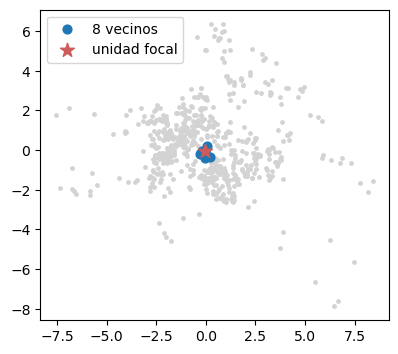

In [16]:
a = pd.read_csv(base + 'airbnb_amsterdam_sample.csv')
lat0, lon0 = a['latitude'].median(), a['longitude'].median()
a['x'] = (a['longitude'] - lon0) * np.cos(np.radians(lat0)) * 111.32
a['yk'] = (a['latitude'] - lat0) * 110.57
a['lp'] = np.log(a['price'])
a['dist'] = np.hypot(a['x'], a['yk'])        # km desde el centro de la muestra

w8 = KNN.from_array(a[['x', 'yk']].values, k=8)
w8.transform = 'r'
print('Alojamientos:', len(a), '| vecinos por unidad:', set(w8.cardinalities.values()))

focal = int(a['dist'].idxmin()); nb = w8.neighbors[focal]
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(a['x'], a['yk'], s=6, color='lightgray'); ax.scatter(a['x'][nb], a['yk'][nb], s=40, label='8 vecinos')
ax.scatter(a['x'][focal], a['yk'][focal], s=110, marker='*', color='indianred', label='unidad focal'); ax.set_aspect('equal'); ax.legend(); plt.show()

**Regresión y mapa de residuos.** Comparamos con los mismos residuos reasignados al azar.

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        5.3358      0.043    123.782      0.000       5.251       5.420
accommodates     0.0881      0.018      4.823      0.000       0.052       0.124
bedrooms         0.1245      0.025      4.897      0.000       0.075       0.174


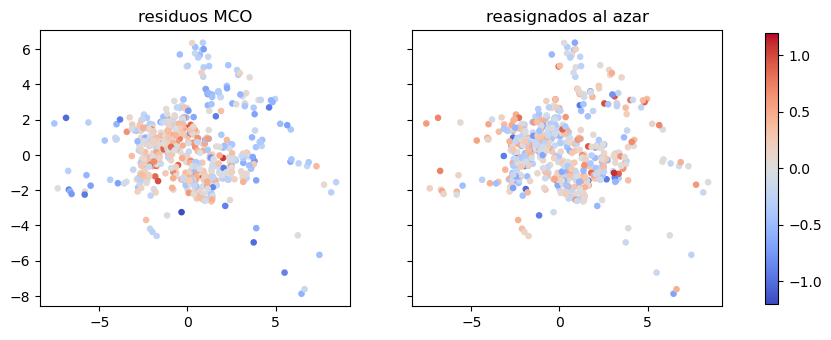

In [17]:
ra = smf.ols('lp ~ accommodates + bedrooms', a).fit()
print(ra.summary().tables[1])

rng = np.random.default_rng(2026)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True, sharey=True)
for aa, v, t in ((ax[0], ra.resid.values, 'residuos MCO'), (ax[1], rng.permutation(ra.resid.values), 'reasignados al azar')):
    sc = aa.scatter(a['x'], a['yk'], c=v, cmap='coolwarm', vmin=-1.2, vmax=1.2, s=14); aa.set_title(t); aa.set_aspect('equal')
plt.colorbar(sc, ax=ax, shrink=.8); plt.show()

**Moran's I y tests LM.** Siempre sobre los **residuos** (la dependencia en $y$ no es dependencia en los errores).

In [18]:
mor_y = Moran(a['lp'].values, w8, permutations=999)
print(f"Moran's I del log precio: {mor_y.I:.2f}")

def diagnostico(cols):
    o = quiet(OLS, a[['lp']].values, a[cols].values, w=w8, spat_diag=True, moran=True)
    perm = Moran(o.u.flatten(), w8, permutations=999)
    return pd.Series({"Moran I (residuos)": perm.I, 'p perm.': perm.p_sim, 'LM-error': o.lm_error[0], 'LM-lag': o.lm_lag[0],
                      'LM-error robusto': o.rlm_error[0], 'LM-lag robusto': o.rlm_lag[0]}).round(3)

tabla = pd.DataFrame({'sin distancia al centro': diagnostico(['accommodates', 'bedrooms']),
                      'con distancia al centro': diagnostico(['accommodates', 'bedrooms', 'dist'])})
print(tabla.to_string())

Moran's I del log precio: 0.14


                    sin distancia al centro  con distancia al centro
Moran I (residuos)                    0.268                    0.086
p perm.                               0.001                    0.001
LM-error                            193.835                   20.050
LM-lag                               96.224                    9.491
LM-error robusto                    138.824                   13.356
LM-lag robusto                       41.213                    2.797


**Síntoma de un problema de especificación:** al agregar la distancia al centro, el Moran de los residuos baja de 0.27 a 0.09 y el LM-error robusto de 139 a 13.

**Errores estándar robustos:** convencional, clusters por barrio y Conley (kernel de Bartlett, radio $h$ en km).

In [19]:
def conley_se(X, resid, xy, cutoff):
    """EE de Conley (HAC espacial): kernel de Bartlett en cada coordenada, cero más allá de `cutoff`."""
    dx = np.abs(xy[:, 0][:, None] - xy[:, 0][None, :]); dy = np.abs(xy[:, 1][:, None] - xy[:, 1][None, :])
    K = np.clip(1 - dx / cutoff, 0, None) * np.clip(1 - dy / cutoff, 0, None)
    S = X * resid[:, None]; bread = np.linalg.inv(X.T @ X)
    return np.sqrt(np.diag(bread @ (S.T @ K @ S) @ bread))

xy = a[['x', 'yk']].values
grupos = a['neighbourhood_cleansed'].astype('category').cat.codes

def tabla_robusta(cols):
    X = sm.add_constant(a[cols]); fit = sm.OLS(a['lp'], X).fit()
    clu = sm.OLS(a['lp'], X).fit(cov_type='cluster', cov_kwds={'groups': grupos})
    j = list(X.columns).index('bedrooms'); b = fit.params['bedrooms']
    se = {'convencional': fit.bse['bedrooms'], 'cluster barrio': clu.bse['bedrooms']}
    for h in (0.5, 1, 2, 5): se[f'Conley h={h} km'] = conley_se(X.values, fit.resid.values, xy, h)[j]
    t = pd.DataFrame({'EE': se}); t['t'] = b / t['EE']; t['cociente'] = t['EE'] / se['convencional']
    return b, t

for etiqueta, cols in (('accommodates + bedrooms', ['accommodates', 'bedrooms']), ('+ dist', ['accommodates', 'bedrooms', 'dist'])):
    b, t = tabla_robusta(cols); print(f'--- {etiqueta}: coef. de bedrooms = {b:.3f}'); print(t.round(3).to_string())

--- accommodates + bedrooms: coef. de bedrooms = 0.124
                    EE      t  cociente
convencional     0.025  4.897     1.000
cluster barrio   0.028  4.445     1.102
Conley h=0.5 km  0.029  4.311     1.136
Conley h=1 km    0.029  4.360     1.123
Conley h=2 km    0.026  4.767     1.027
Conley h=5 km    0.025  5.010     0.978
--- + dist: coef. de bedrooms = 0.166
                    EE      t  cociente
convencional     0.023  7.329     1.000
cluster barrio   0.022  7.499     0.977
Conley h=0.5 km  0.023  7.282     1.006
Conley h=1 km    0.022  7.438     0.985
Conley h=2 km    0.021  7.816     0.938
Conley h=5 km    0.019  8.560     0.856


**Modelos espaciales (SEM y SAR)** con la distancia al centro. En SAR $\beta$ no es el efecto marginal: hay efecto **directo**, **indirecto** (derrames) y **total** a partir de $(I-\rho W)^{-1}$.

In [20]:
cols = ['accommodates', 'bedrooms', 'dist']
y_, X_ = a[['lp']].values, a[cols].values
ols = quiet(OLS, y_, X_, w=w8)
sem = quiet(ML_Error, y_, X_, w=w8); sar = quiet(ML_Lag, y_, X_, w=w8)
print(f'bedrooms: MCO = {np.asarray(ols.betas).flatten()[2]:.3f} | SEM = {np.asarray(sem.betas).flatten()[2]:.3f} (EE {np.asarray(sem.std_err).flatten()[2]:.3f}) | SAR = {np.asarray(sar.betas).flatten()[2]:.3f}')
print(f'lambda (SEM) = {float(sem.lam):.2f} | rho (SAR) = {float(sar.rho):.2f}')

A = np.linalg.inv(np.eye(w8.n) - float(sar.rho) * w8.full()[0]); b_sar = np.asarray(sar.betas).flatten()[2]
directo, total = np.trace(A) / w8.n * b_sar, A.sum() / w8.n * b_sar
print(f'Efecto de un dormitorio adicional: directo = {directo:.3f}, indirecto = {total - directo:.3f}, total = {total:.3f}')

bedrooms: MCO = 0.166 | SEM = 0.160 (EE 0.022) | SAR = 0.165
lambda (SEM) = 0.30 | rho (SAR) = 0.21
Efecto de un dormitorio adicional: directo = 0.166, indirecto = 0.043, total = 0.209


**Un puente con la EAH.** Los errores de personas de la misma comuna comparten componentes. Con clusters por comuna, el error estándar de la escolaridad casi se duplica: parte de la varianza de `aesc` es entre comunas y también la hay en los residuos.

In [21]:
g = d.groupby('comuna')
for v in ('aesc', 'res'):
    entre = ((g[v].transform('mean') - d[v].mean()) ** 2).sum() / ((d[v] - d[v].mean()) ** 2).sum()
    print(f'{v}: {100 * entre:.1f}% de la varianza es entre comunas')
b, t = tabla_se('y ~ aesc + mujer'); print(t.round(4).to_string())

aesc: 12.9% de la varianza es entre comunas
res: 1.5% de la varianza es entre comunas
                EE aesc   t aesc  EE mujer
convencional     0.0020  50.2802    0.0151
HC1              0.0020  50.8514    0.0150
HC3              0.0020  50.8340    0.0150
cluster hogar    0.0021  48.4668    0.0145
cluster comuna   0.0037  27.4434    0.0203


## 5. Práctica

1. (EAH) Estimen `y ~ aesc + mujer + edad + I(edad**2)`. Hagan el test de Breusch-Pagan y comparen errores convencionales, HC1 y clusters por comuna.
2. (EMAE) Agreguen dummies mensuales a la tendencia y recalculen DW y el EE HAC para $L=4, 12, 24$.
3. (EMAE) Repitan la simulación de cobertura con $\rho_x=0$: ¿qué pasa con el cociente entre el EE convencional y la dispersión verdadera?
4. (Ámsterdam) Cambien $W$ a 4 y a 16 vecinos y comparen el Moran de los residuos y los tests LM.
5. (Ámsterdam) Calculen el EE de Conley para `accommodates` con $h=0.5, 1, 2, 5$ km. ¿Se estabiliza?

In [22]:
# Espacio para trabajar